In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# load clean data
df = pd.read_csv("C:\\Users\\suraj\\Downloads\\henderson_clean_final_data.csv", index_col="datetime", parse_dates=True)
df.head()

,NO2,PM10,RH,Temp,WS
datetime,,,,,
2006-01-01 00:00:00,1.50,18.4,80.3,19.0,1.3
2006-01-01 01:00:00,0.76,32.6,81.1,19.0,3.1
2006-01-01 02:00:00,0.46,18.6,80.4,20.0,2.7
2006-01-01 03:00:00,0.42,15.1,79.4,20.0,1.6
2006-01-01 04:00:00,0.40,15.6,80.4,20.0,1.4


          PM10   NO2
datetime            
2006      0.99  0.99
2007      0.99  0.99
2008      0.99  0.99
2009      1.00  1.00
2010      1.00  1.00
2011      1.00  0.99
2012      1.00  0.99
2013      1.00  0.99
2014      0.99  0.99
2015      0.93  0.93
2016      0.99  0.99
2017      0.98  0.58
2018      0.88  0.13
2019      0.99  0.98
2020      1.00  1.00
2021      0.99  1.00
2022      0.81  0.82
2023      1.00  0.99


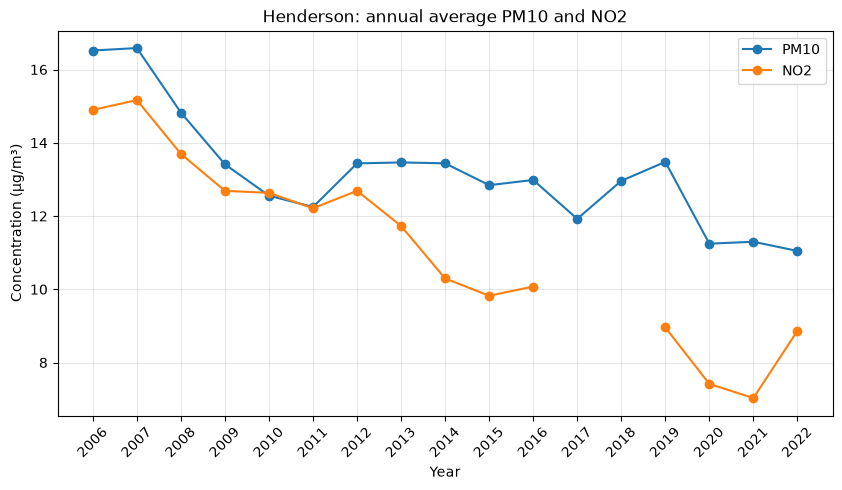

In [2]:
# yearly average and % of hours with data
yearly_mean = df[["PM10", "NO2"]].groupby(df.index.year).mean()
coverage = df[["PM10", "NO2"]].notna().groupby(df.index.year).mean()

# hide years with less than 75% data
yearly_mean = yearly_mean.where(coverage >= 0.75)
# 2023 only has Jan-Feb, so drop it
yearly_mean = yearly_mean.loc[:2022]

print(coverage.round(2))
yearly_mean.round(1)

# plot the trend
yearly_mean.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: annual average PM10 and NO2")
plt.xlabel("Year")
plt.ylabel("Concentration (µg/m³)")
plt.grid(alpha=0.3)
plt.xticks(yearly_mean.index, rotation=45)
plt.show()

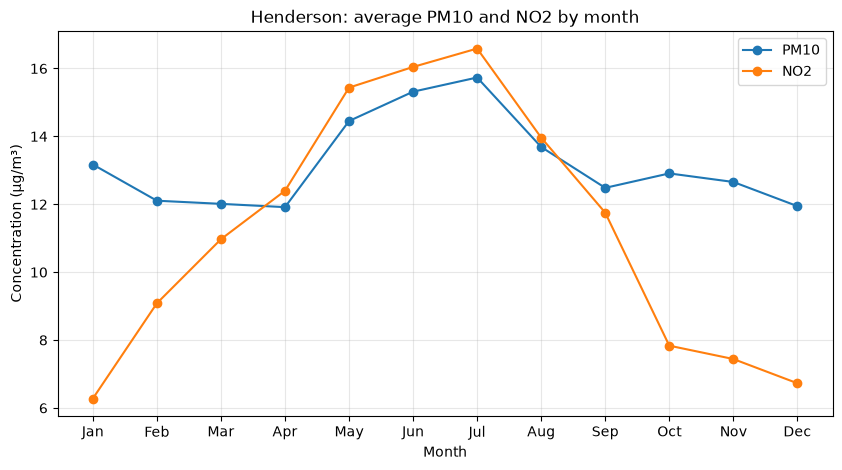

In [3]:
# average for each month across all years
monthly = df[["PM10", "NO2"]].groupby(df.index.month).mean()

# plot
monthly.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: average PM10 and NO2 by month")
plt.xlabel("Month")
plt.ylabel("Concentration (µg/m³)")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.grid(alpha=0.3)
plt.show()

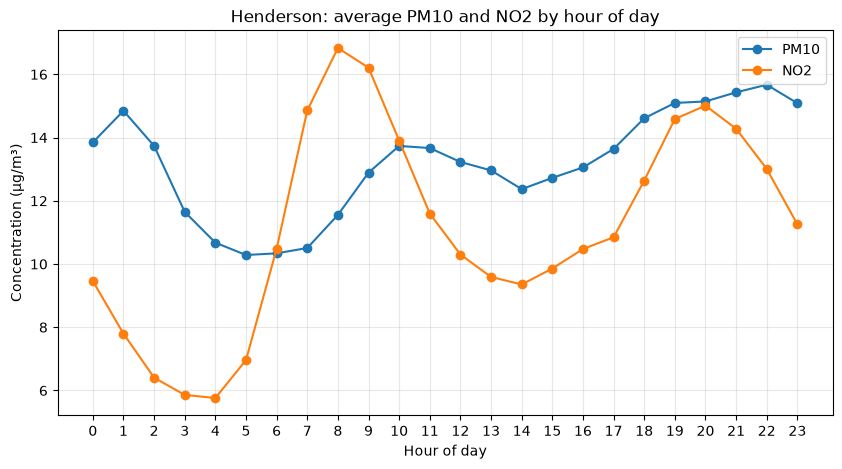

In [4]:
# average for each hour of the day across all years
hourly = df[["PM10", "NO2"]].groupby(df.index.hour).mean()

# plot
hourly.plot(marker="o", figsize=(10, 5))
plt.title("Henderson: average PM10 and NO2 by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Concentration (µg/m³)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

        PM10   NO2
Season            
Summer  12.4   7.3
Autumn  12.8  13.0
Winter  14.9  15.6
Spring  12.7   9.0


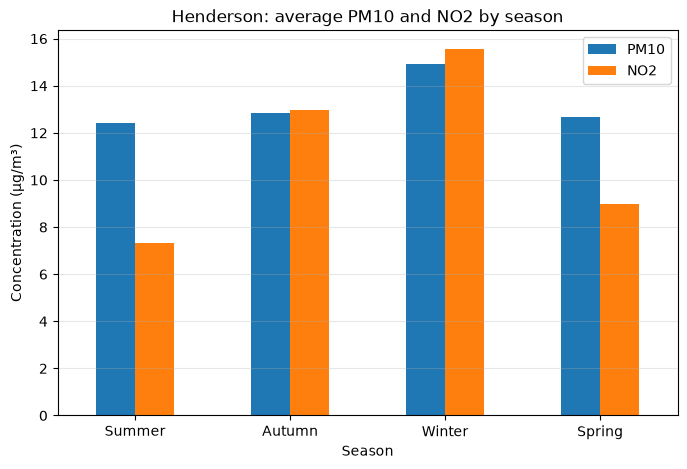

In [5]:
# map each month to an NZ season
season_map = {12: "Summer", 1: "Summer", 2: "Summer",
              3: "Autumn", 4: "Autumn", 5: "Autumn",
              6: "Winter", 7: "Winter", 8: "Winter",
              9: "Spring", 10: "Spring", 11: "Spring"}
df["Season"] = df.index.month.map(season_map)

# average per season, in calendar order
order = ["Summer", "Autumn", "Winter", "Spring"]
by_season = df.groupby("Season")[["PM10", "NO2"]].mean().loc[order]
print(by_season.round(1))

# bar chart
by_season.plot(kind="bar", figsize=(8, 5), rot=0)
plt.title("Henderson: average PM10 and NO2 by season")
plt.xlabel("Season")
plt.ylabel("Concentration (µg/m³)")
plt.grid(axis="y", alpha=0.3)
plt.show()

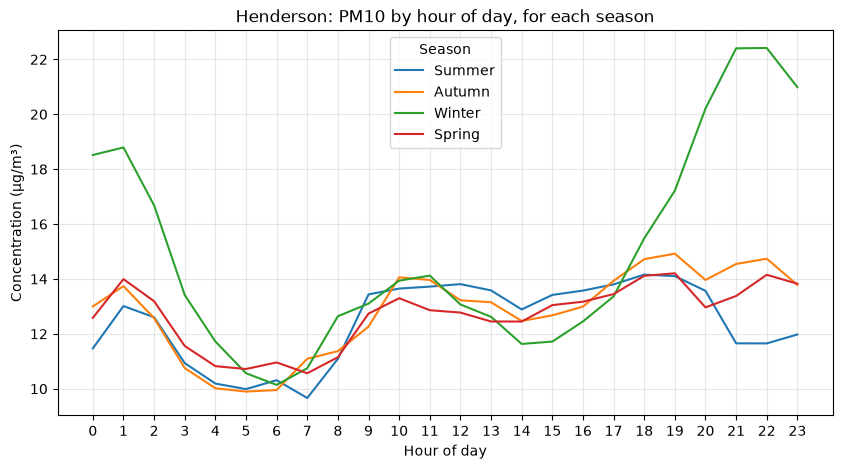

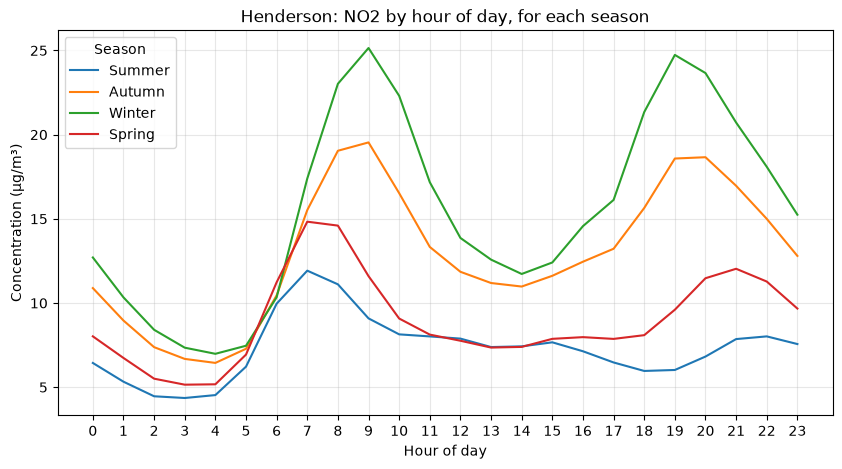

In [6]:
# daily pattern for each season
for col in ["PM10", "NO2"]:
    season_hour = df.groupby(["Season", df.index.hour])[col].mean().unstack(0)[order]
    season_hour.plot(figsize=(10, 5))
    plt.title(f"Henderson: {col} by hour of day, for each season")
    plt.xlabel("Hour of day")
    plt.ylabel("Concentration (µg/m³)")
    plt.xticks(range(0, 24))
    plt.grid(alpha=0.3)
    plt.show()

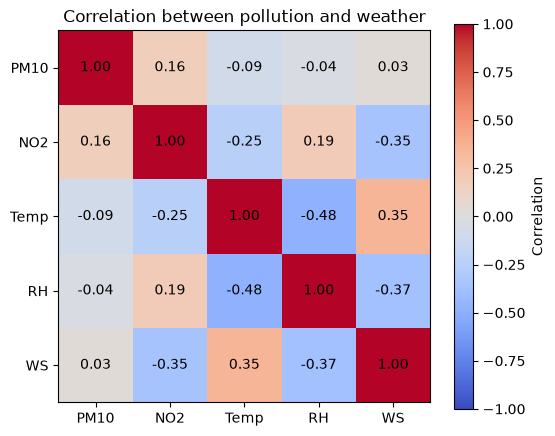

In [7]:
# correlation between all variables (-1 to 1)
# only the numeric columns (Season is text, so it is left out)
corr = df[["PM10", "NO2", "Temp", "RH", "WS"]].corr()
corr.round(2)


# heatmap of the correlations
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr)), corr.columns)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Correlation between pollution and weather")
plt.show()

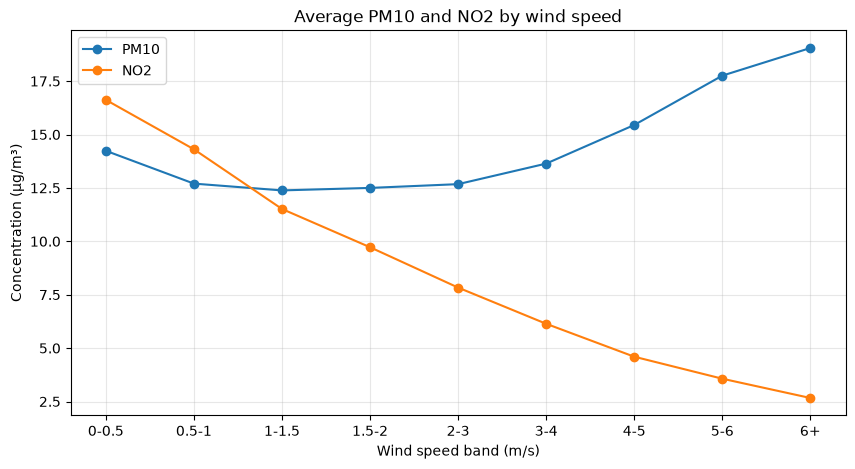

In [8]:
# group wind speed into bands
bins = [0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 11]
df["WS_band"] = pd.cut(df["WS"], bins=bins, include_lowest=True)

# average pollution in each band
by_wind = df.groupby("WS_band", observed=True)[["PM10", "NO2"]].mean()

# plot
by_wind.plot(marker="o", figsize=(10, 5))
plt.title("Average PM10 and NO2 by wind speed")
plt.xlabel("Wind speed band (m/s)")
plt.ylabel("Concentration (µg/m³)")
plt.grid(alpha=0.3)
plt.xticks(range(len(by_wind)), ["0-0.5", "0.5-1", "1-1.5", "1.5-2", "2-3", "3-4", "4-5", "5-6", "6+"])
plt.show()


# remove the helper column
df = df.drop(columns="WS_band")

                                            feature engineering

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("C:\\Users\\suraj\\Downloads\\henderson_clean_final_data.csv", index_col="datetime", parse_dates=True)
df.head()

,NO2,PM10,RH,Temp,WS
datetime,,,,,
2006-01-01 00:00:00,1.50,18.4,80.3,19.0,1.3
2006-01-01 01:00:00,0.76,32.6,81.1,19.0,3.1
2006-01-01 02:00:00,0.46,18.6,80.4,20.0,2.7
2006-01-01 03:00:00,0.42,15.1,79.4,20.0,1.6
2006-01-01 04:00:00,0.40,15.6,80.4,20.0,1.4


In [11]:
def make_features(df, target):
    X = pd.DataFrame(index=df.index)

    # time features
    X["hour"] = df.index.hour
    X["month"] = df.index.month
    X["dayofweek"] = df.index.dayofweek
    X["is_weekend"] = (X["dayofweek"] >= 5).astype(int)

    # current weather
    for col in ["Temp", "RH", "WS"]:
        X[col] = df[col]

    # past pollution values (lag0 = now, lag1 = 1 hour ago, lag24 = same time yesterday)
    for lag in [0, 1, 2, 3, 24]:
        X[f"{target}_lag{lag}"] = df[target].shift(lag)

    # recent averages
    X[f"{target}_roll3"] = df[target].rolling(3).mean()
    X[f"{target}_roll24"] = df[target].rolling(24).mean()

    # target = value next hour
    y = df[target].shift(-1).rename("target")

    # drop rows with any missing value
    return pd.concat([X, y], axis=1).dropna()

In [12]:
# build data for each pollutant and split by time
# build data for each pollutant and split 80/20 by time (no shuffling)
data = {}
for t in ["PM10", "NO2"]:
    d = make_features(df, t)
    cut = int(len(d) * 0.8)
    data[t] = {"train": d.iloc[:cut], "test": d.iloc[cut:]}
    print(t, "train:", len(data[t]["train"]), data[t]["train"].index.min(), "to", data[t]["train"].index.max())
    print(t, "test: ", len(data[t]["test"]), data[t]["test"].index.min(), "to", data[t]["test"].index.max())

PM10 train: 103984 2006-01-02 00:00:00 to 2018-07-21 03:00:00
PM10 test:  25997 2018-07-21 04:00:00 to 2023-01-31 23:00:00
NO2 train: 97396 2006-01-02 00:00:00 to 2017-07-15 06:00:00
NO2 test:  24350 2017-07-15 07:00:00 to 2023-01-31 23:00:00


In [13]:
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [15]:
# helper functions: metrics, actual vs predicted plot, run one model
# NEW (supervisor feedback): actual vs predicted now shows DATES on the x-axis
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

# two example weeks from the test set (with dates) + scatter of the whole test set
def plot_model(t, name, start="2019-07-01", end="2019-07-14"):
    test = data[t]["test"]
    actual = test["target"]
    pred = pd.Series(predictions[(t, name)], index=test.index)
    m = evaluate(actual, pred)

    fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [3, 1]})

    axes[0].plot(actual.loc[start:end], label=f"Actual {t}", color="tab:blue", linewidth=1.5)
    axes[0].plot(pred.loc[start:end], label=f"Predicted {t}", color="tab:orange", linewidth=1.5)
    axes[0].set_title(f"{t}: Actual vs Predicted - {name} ({start} to {end})")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel(f"{t} Concentration (µg/m³)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].scatter(actual, pred, s=4, alpha=0.3)
    lim = [0, max(actual.max(), pred.max())]
    axes[1].plot(lim, lim, color="red", linestyle="--", label="Perfect prediction")
    axes[1].set_title("Whole test set")
    axes[1].set_xlabel("Actual")
    axes[1].set_ylabel("Predicted")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"{t} — {name}   |   MAE = {m['MAE']:.2f}   RMSE = {m['RMSE']:.2f}   R² = {m['R2']:.3f}",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

results = []
predictions = {}

# train one model on both pollutants, print metrics, plot
def run_model(name, model):
    for t in ["PM10", "NO2"]:
        X_train = data[t]["train"].drop(columns="target")
        y_train = data[t]["train"]["target"]
        X_test = data[t]["test"].drop(columns="target")
        y_test = data[t]["test"]["target"]

        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        predictions[(t, name)] = pred

        m = evaluate(y_test, pred)
        results.append({"Target": t, "Model": name, **m})
        print(f"{name} — {t}:  MAE = {m['MAE']:.3f}   RMSE = {m['RMSE']:.3f}   R² = {m['R2']:.3f}")

        plot_model(t, name)

In [16]:
# naive baseline: next hour = this hour (reference point, not one of the six models)
for t in ["PM10", "NO2"]:
    test = data[t]["test"]
    results.append({"Target": t, "Model": "Naive baseline",
                    **evaluate(test["target"], test[f"{t}_lag0"])})
pd.DataFrame(results).round(3)

,Target,Model,MAE,RMSE,R2
0,PM10,Naive baseline,5.195,7.076,0.057
1,NO2,Naive baseline,2.858,4.892,0.655


Linear Regression — PM10:  MAE = 4.402   RMSE = 6.004   R² = 0.321


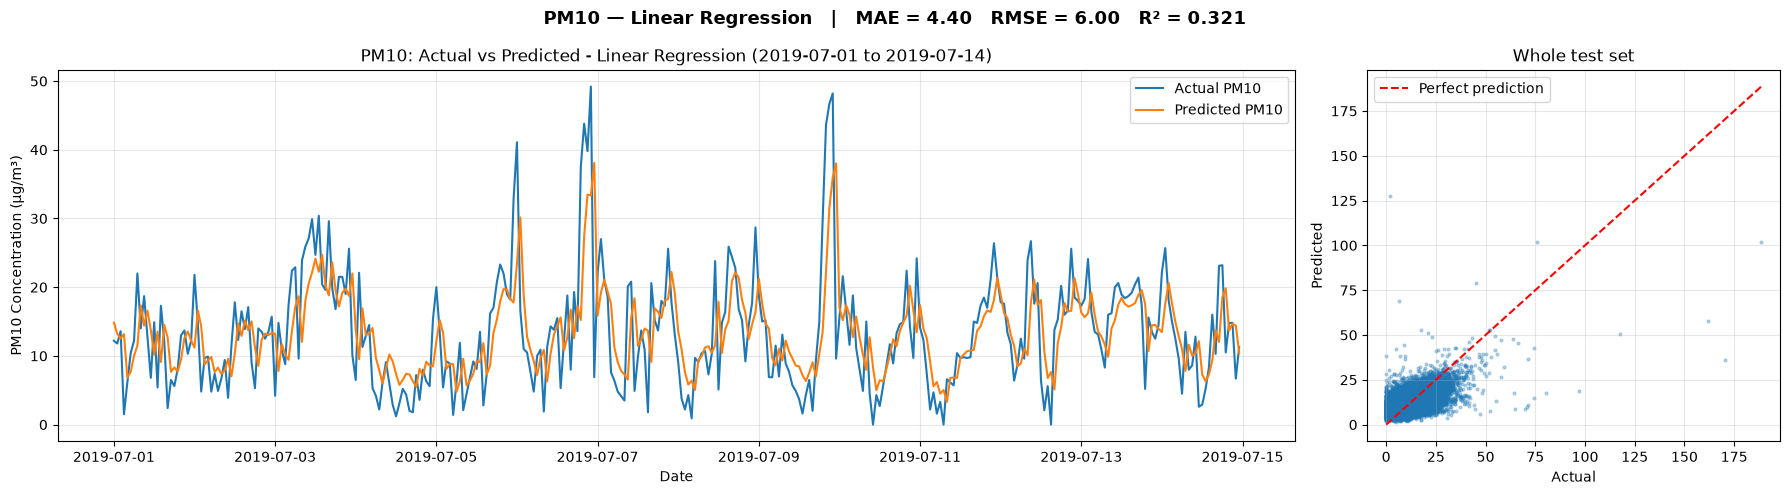

Linear Regression — NO2:  MAE = 2.926   RMSE = 4.519   R² = 0.706


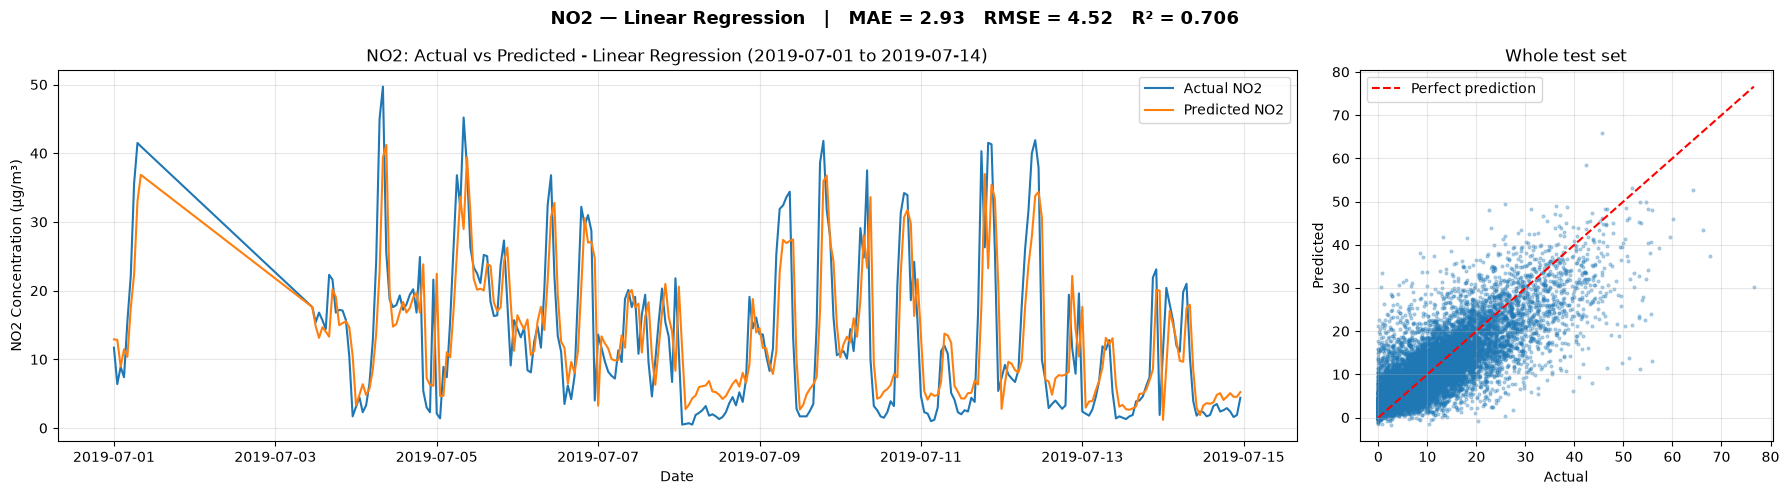

In [17]:
# Model 1: Linear Regression
from sklearn.linear_model import LinearRegression
run_model("Linear Regression", LinearRegression())

Decision Tree — PM10:  MAE = 4.339   RMSE = 6.130   R² = 0.292


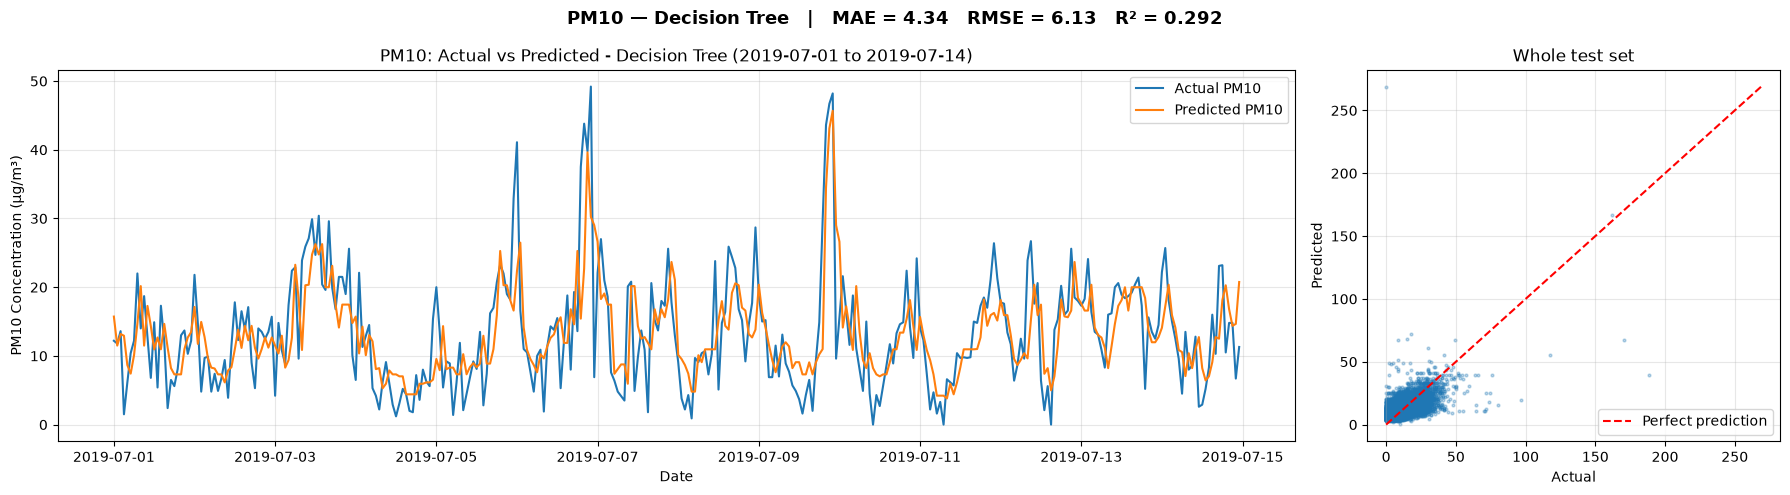

Decision Tree — NO2:  MAE = 2.791   RMSE = 4.511   R² = 0.707


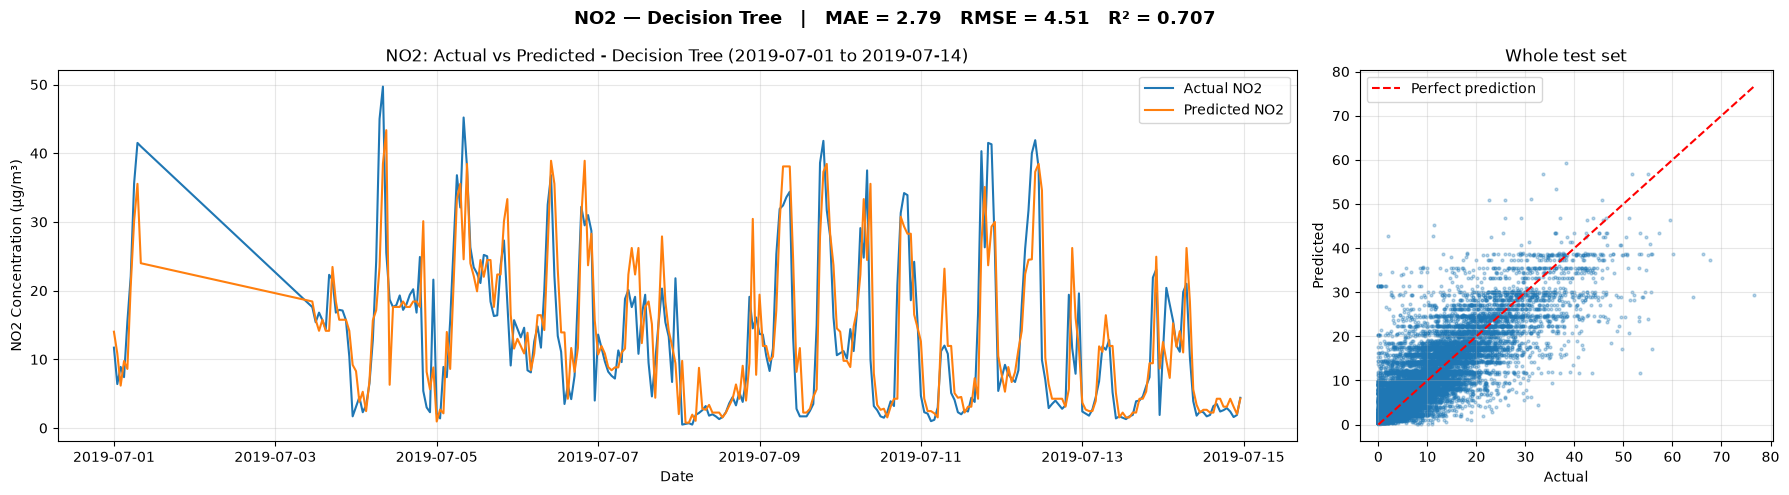

In [18]:
# Model 2: Decision Tree
from sklearn.tree import DecisionTreeRegressor
run_model("Decision Tree", DecisionTreeRegressor(max_depth=10, random_state=42))

Random Forest — PM10:  MAE = 4.202   RMSE = 5.789   R² = 0.369


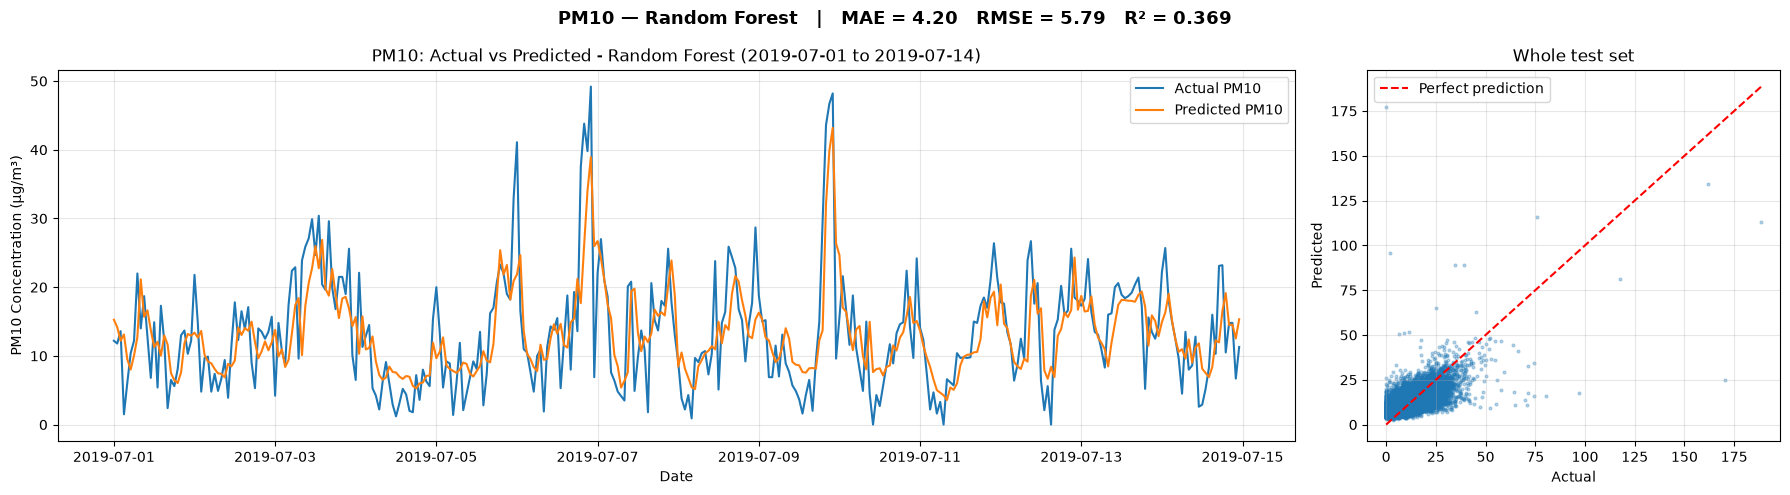

Random Forest — NO2:  MAE = 2.602   RMSE = 4.111   R² = 0.757


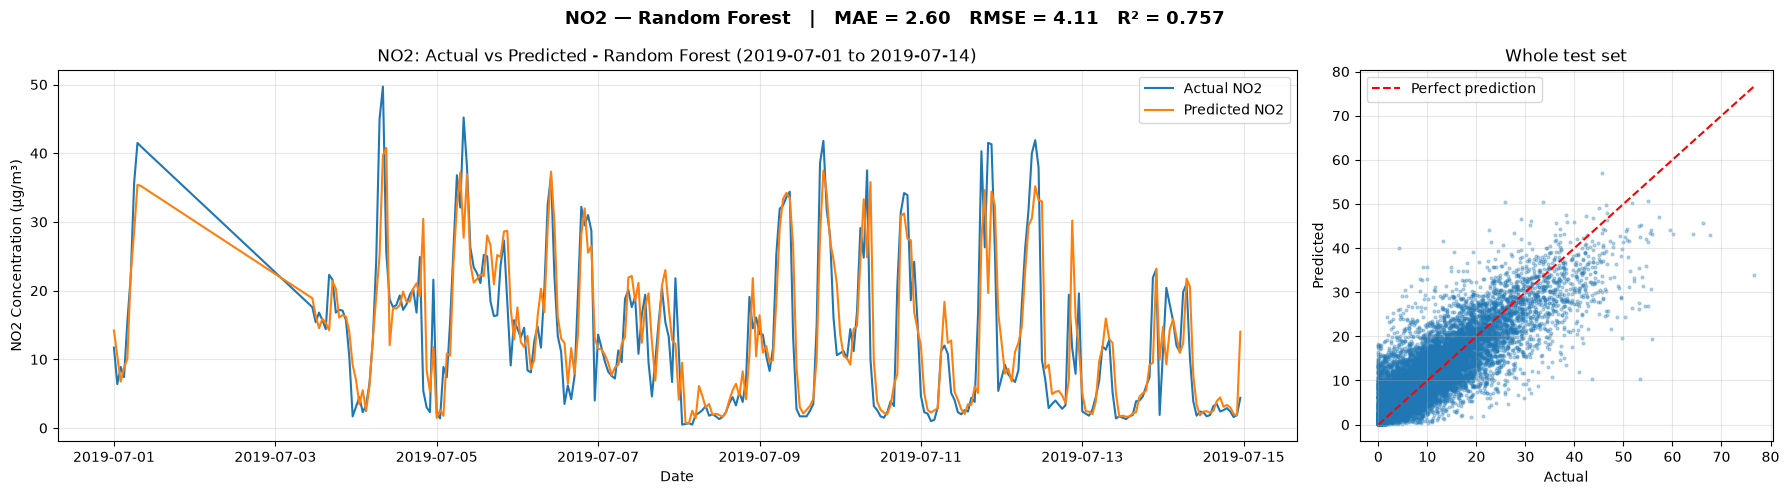

In [19]:
# Model 3: Random Forest
from sklearn.ensemble import RandomForestRegressor
run_model("Random Forest", RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42))

XGBoost (tuned) — PM10:  MAE = 4.168   RMSE = 5.781   R² = 0.370


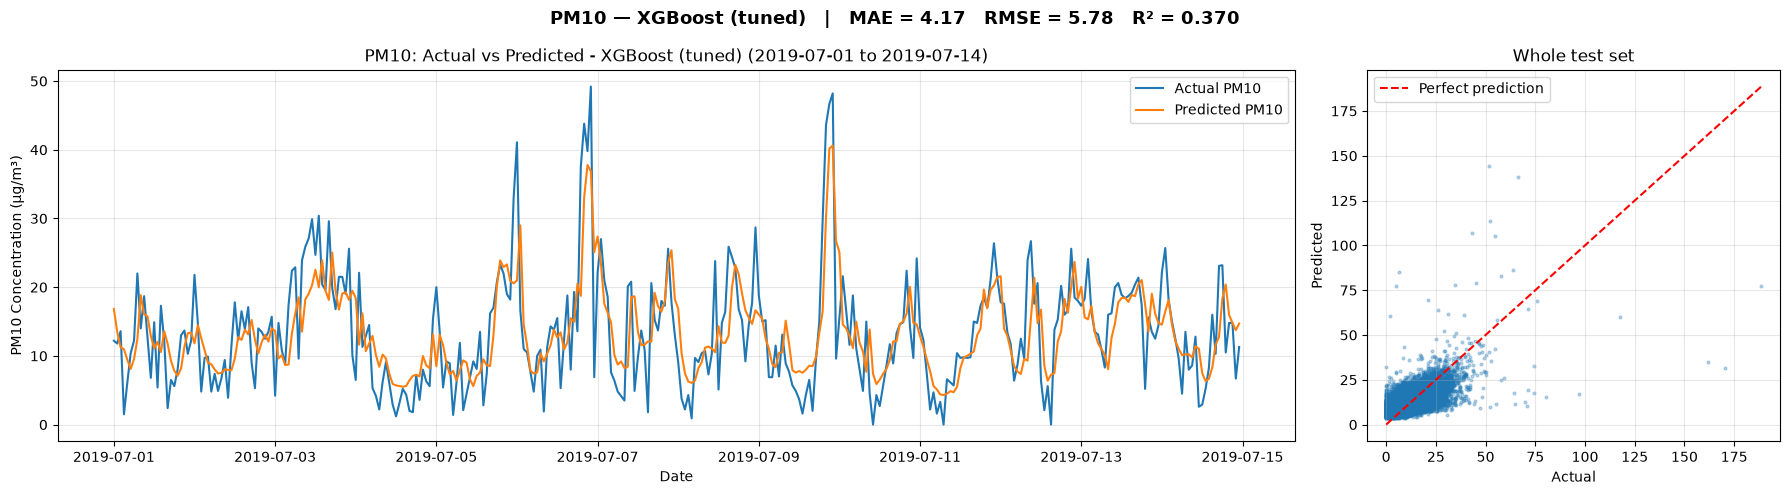

XGBoost (tuned) — NO2:  MAE = 2.559   RMSE = 3.999   R² = 0.770


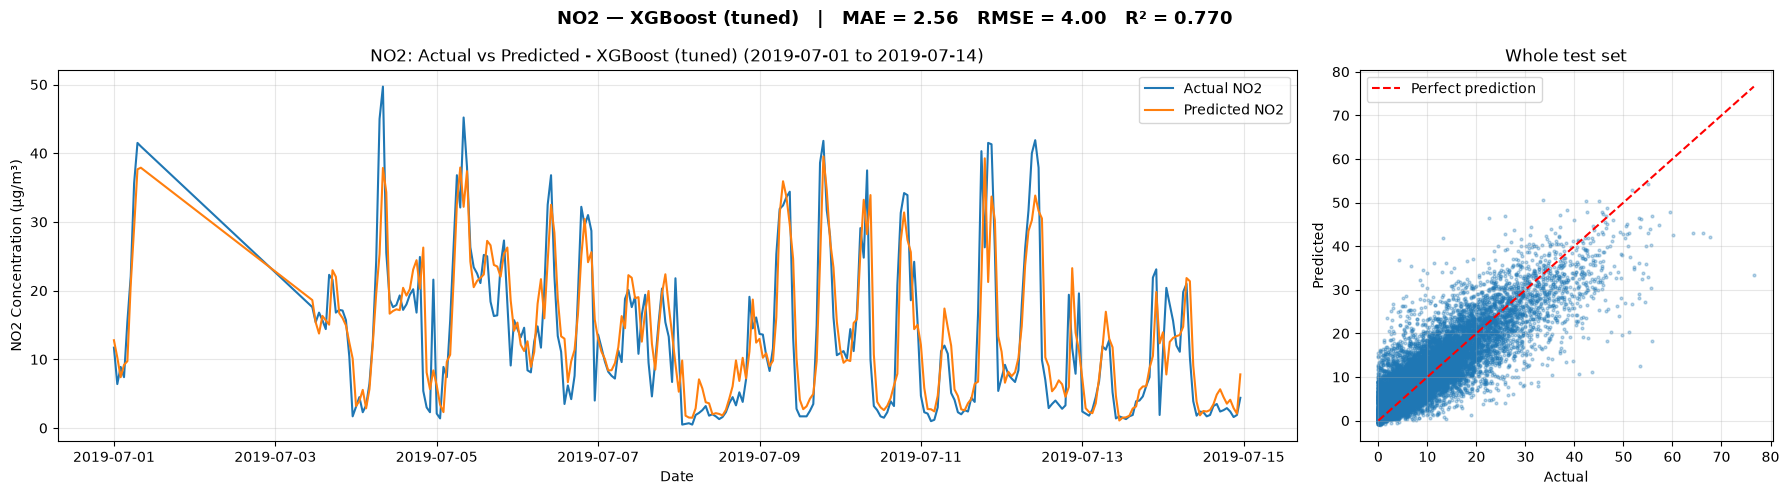

In [20]:
# Model 4b: XGBoost with stricter settings
run_model("XGBoost (tuned)", XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                          min_child_weight=20, random_state=42))

LightGBM — PM10:  MAE = 4.134   RMSE = 5.738   R² = 0.380


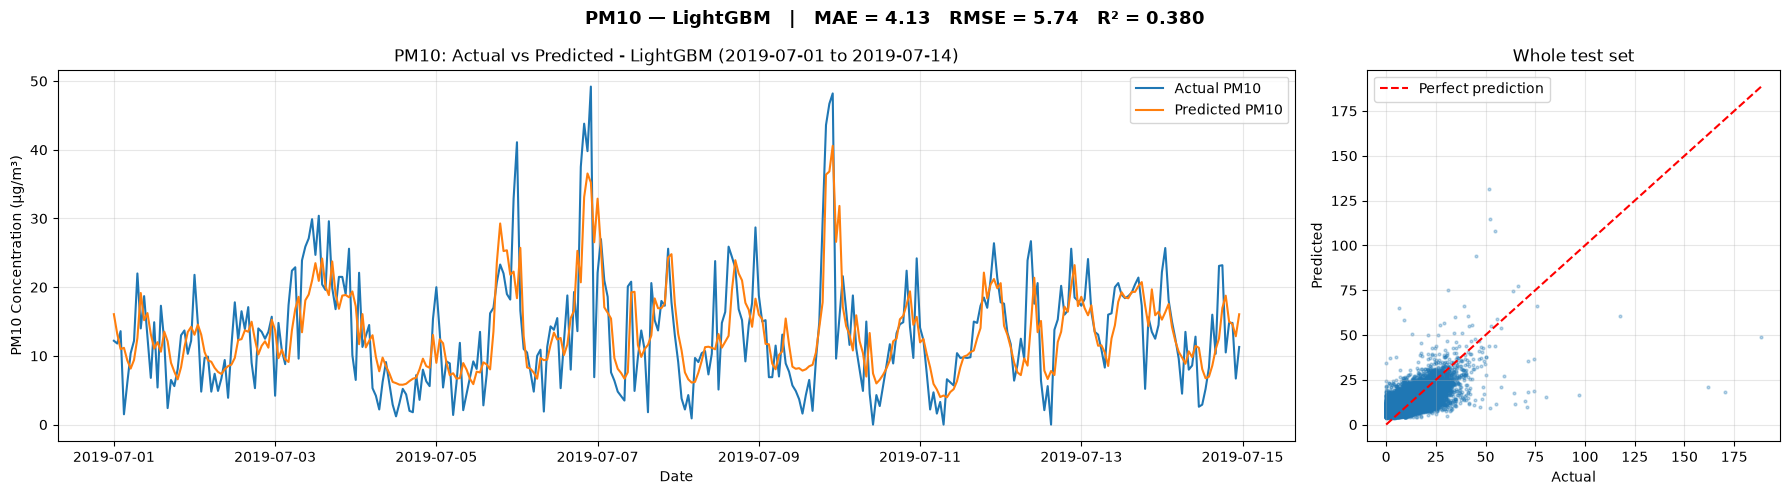

LightGBM — NO2:  MAE = 2.487   RMSE = 3.891   R² = 0.782


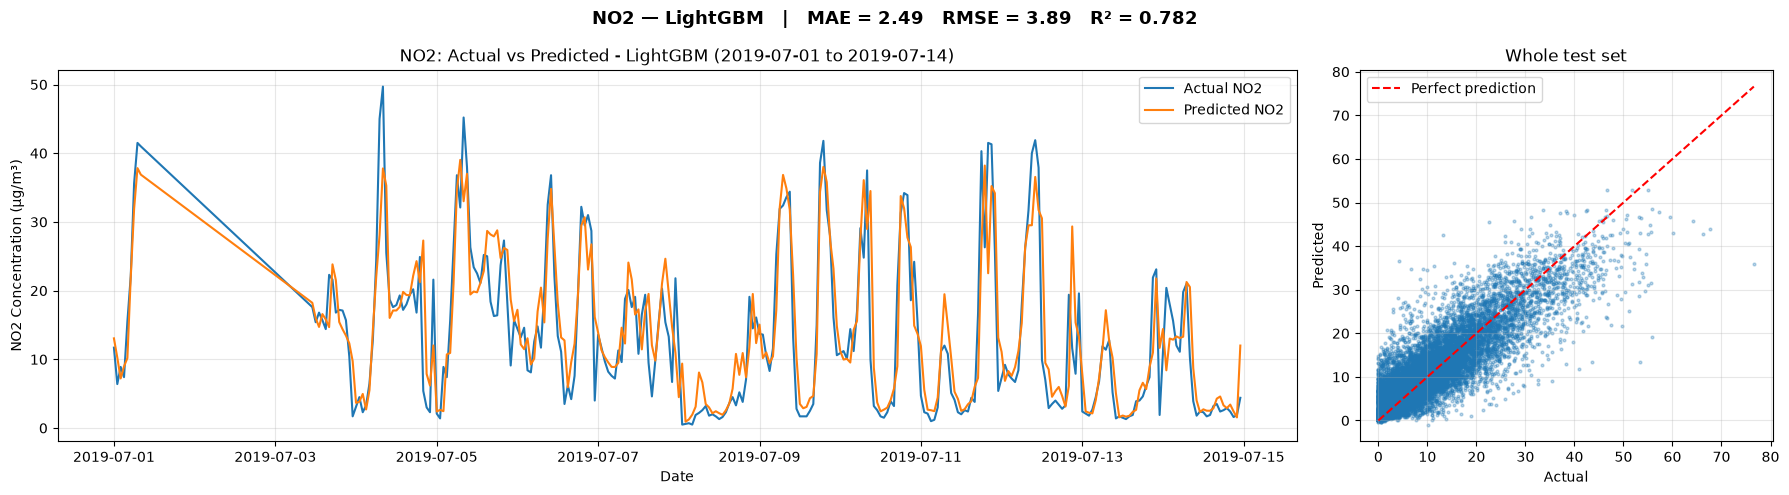

In [21]:
# Model 5: LightGBM
from lightgbm import LGBMRegressor
run_model("LightGBM", LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1))

In [22]:
# final comparison: drop the original XGBoost, keep the tuned one
res = pd.DataFrame(results).drop_duplicates(subset=["Target", "Model"], keep="last")
res = res[res["Model"] != "XGBoost"].round(3)
res.sort_values(["Target", "R2"], ascending=[True, False])

,Target,Model,MAE,RMSE,R2
11,NO2,LightGBM,2.487,3.891,0.782
9,NO2,XGBoost (tuned),2.559,3.999,0.770
7,NO2,Random Forest,2.602,4.111,0.757
5,NO2,Decision Tree,2.791,4.511,0.707
3,NO2,Linear Regression,2.926,4.519,0.706
1,NO2,Naive baseline,2.858,4.892,0.655
10,PM10,LightGBM,4.134,5.738,0.380
8,PM10,XGBoost (tuned),4.168,5.781,0.370
6,PM10,Random Forest,4.202,5.789,0.369
2,PM10,Linear Regression,4.402,6.004,0.321


In [23]:
%pip install prophet

Note: you may need to restart the kernel to use updated packages.


20:01:16 - cmdstanpy - INFO - Chain [1] start processing
20:02:23 - cmdstanpy - INFO - Chain [1] done processing


Prophet — PM10:  MAE = 5.331   RMSE = 7.201   R² = 0.023


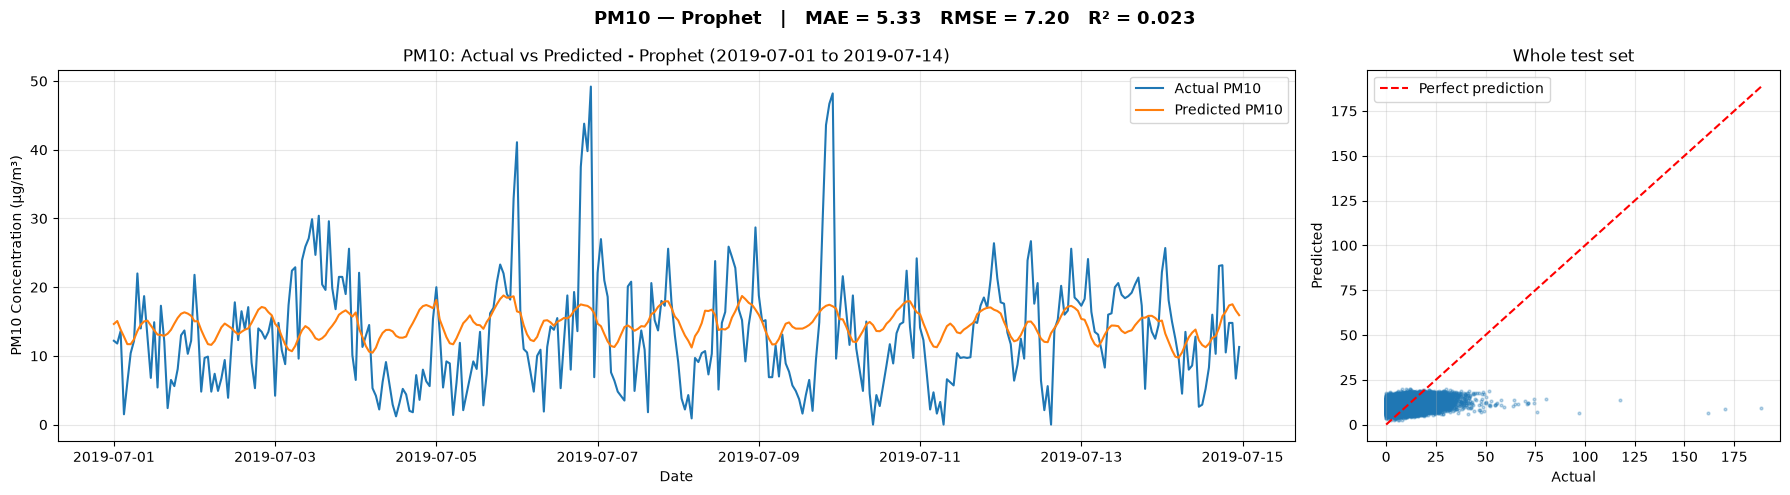

20:02:53 - cmdstanpy - INFO - Chain [1] start processing
20:03:43 - cmdstanpy - INFO - Chain [1] done processing


Prophet — NO2:  MAE = 5.464   RMSE = 7.091   R² = 0.276


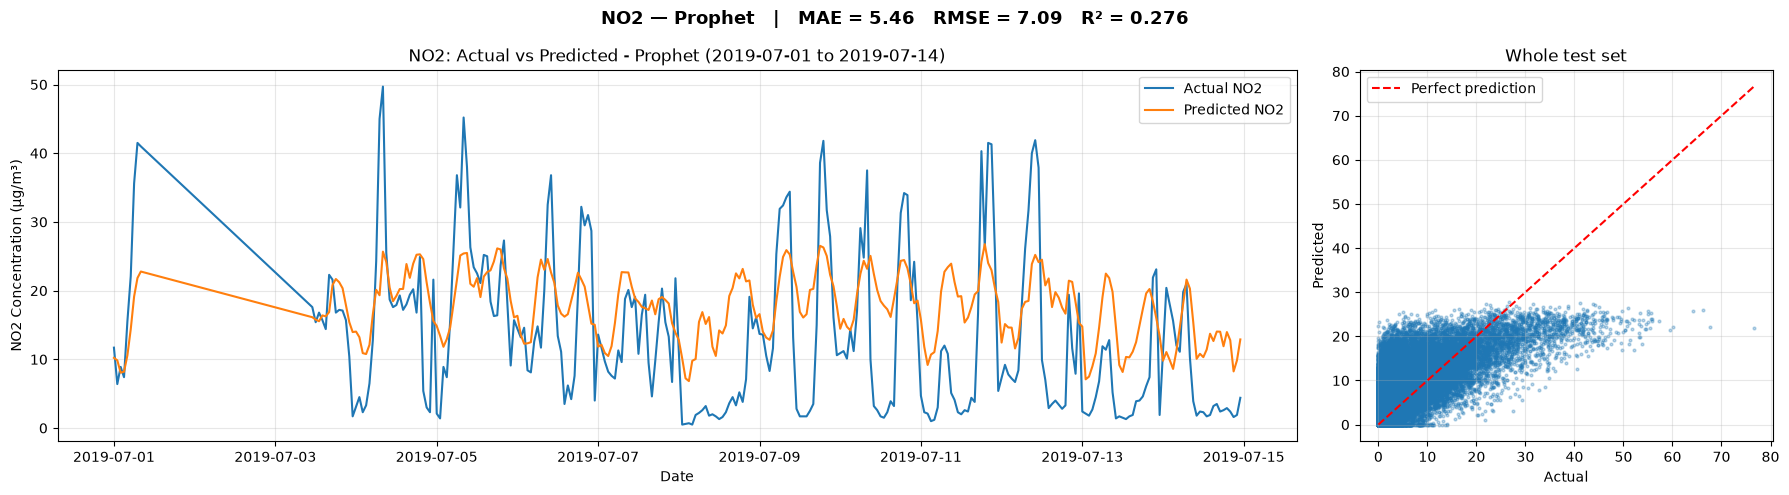

In [24]:
# Model 6: Prophet
from prophet import Prophet

for t in ["PM10", "NO2"]:
    train, test = data[t]["train"], data[t]["test"]

    # Prophet needs columns: ds (time), y (value) + weather regressors
    # target is next hour, so ds = this hour + 1
    def to_prophet(d):
        return pd.DataFrame({"ds": d.index + pd.Timedelta(hours=1),
                             "y": d["target"].values,
                             "Temp": d["Temp"].values,
                             "RH": d["RH"].values,
                             "WS": d["WS"].values})

    p_train, p_test = to_prophet(train), to_prophet(test)

    # build model with daily, weekly, yearly patterns + weather
    m = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True)
    for reg in ["Temp", "RH", "WS"]:
        m.add_regressor(reg)
    m.fit(p_train)

    # predict the test set
    pred = m.predict(p_test.drop(columns="y"))["yhat"].clip(lower=0).values
    predictions[(t, "Prophet")] = pred

    # metrics + graph
    score = evaluate(test["target"], pred)
    results.append({"Target": t, "Model": "Prophet", **score})
    print(f"Prophet — {t}:  MAE = {score['MAE']:.3f}   RMSE = {score['RMSE']:.3f}   R² = {score['R2']:.3f}")
    plot_model(t, "Prophet")

In [25]:
# compare all models (no baseline, no original XGBoost)
res = pd.DataFrame(results).drop_duplicates(subset=["Target", "Model"], keep="last")
res = res[~res["Model"].isin(["XGBoost", "Naive baseline"])].round(3)
res.sort_values(["Target", "R2"], ascending=[True, False])

,Target,Model,MAE,RMSE,R2
11,NO2,LightGBM,2.487,3.891,0.782
9,NO2,XGBoost (tuned),2.559,3.999,0.770
7,NO2,Random Forest,2.602,4.111,0.757
5,NO2,Decision Tree,2.791,4.511,0.707
3,NO2,Linear Regression,2.926,4.519,0.706
13,NO2,Prophet,5.464,7.091,0.276
10,PM10,LightGBM,4.134,5.738,0.380
8,PM10,XGBoost (tuned),4.168,5.781,0.370
6,PM10,Random Forest,4.202,5.789,0.369
2,PM10,Linear Regression,4.402,6.004,0.321


In [26]:
# Keep only the six final models (no baseline, no untuned XGBoost).

comparable_results = (

    res[
        ~res[
            'Model'
        ].isin(
            ['Naive baseline', 'XGBoost']
        )
    ]

    .copy()
)

# Pick the model with the lowest RMSE for each pollutant.

best_models = (

    comparable_results

    .sort_values(
        'RMSE'
    )

    .groupby(
        'Target',
        as_index=False
    )

    .first()
)

print(
    "Best one-hour-ahead model for PM10 and NO2:"
)

display(
    best_models
)

Best one-hour-ahead model for PM10 and NO2:


,Target,Model,MAE,RMSE,R2
0,NO2,LightGBM,2.487,3.891,0.782
1,PM10,LightGBM,4.134,5.738,0.380


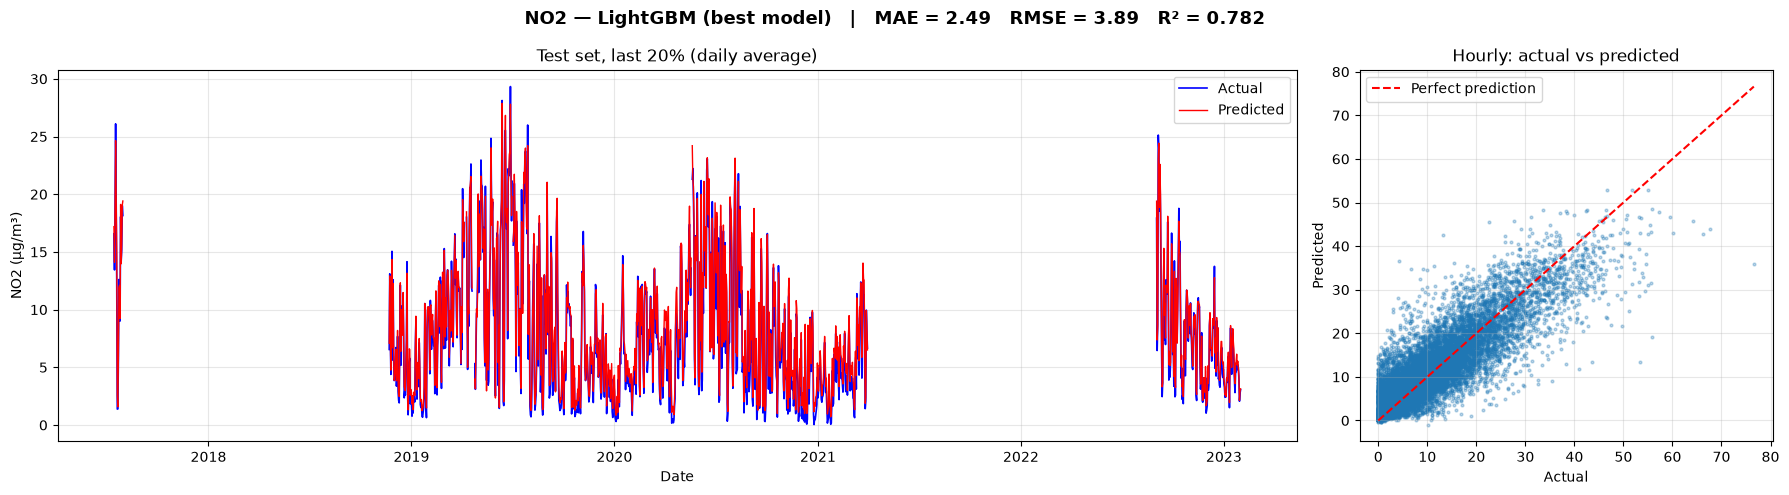

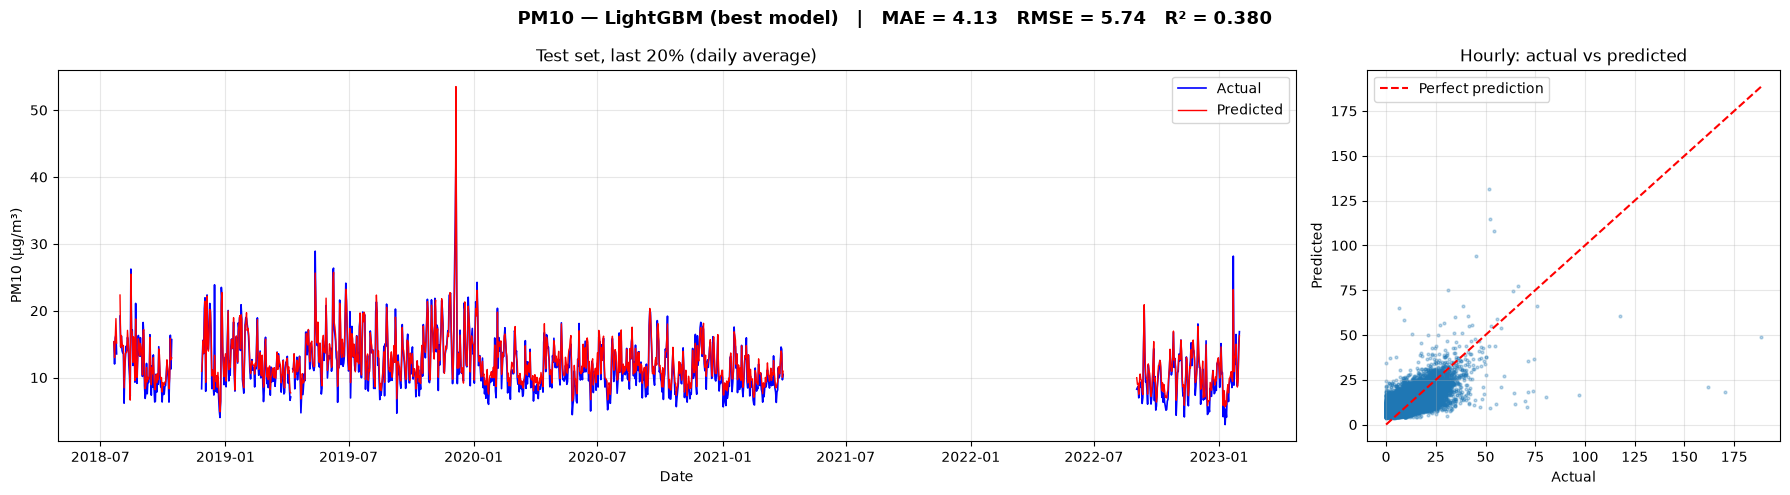

In [27]:
# One figure per best model: full-year actual vs predicted + scatter.

for _, row in best_models.iterrows():

    t, name = row['Target'], row['Model']
    test = data[t]['test']
    actual = test['target']
    pred = pd.Series(predictions[(t, name)], index=test.index)
    m = evaluate(actual, pred)

    fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [3, 1]})

    # full year, daily averages
    axes[0].plot(actual.resample('D').mean(), label='Actual', color='blue', linewidth=1.2)
    axes[0].plot(pred.resample('D').mean(), label='Predicted', color='red', linewidth=1)
    axes[0].set_title('Test set, last 20% (daily average)')
    axes[0].set_xlabel('Date')
    axes[0].set_ylabel(f"{t} (µg/m³)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # scatter, hourly
    axes[1].scatter(actual, pred, s=4, alpha=0.3)
    lim = [0, max(actual.max(), pred.max())]
    axes[1].plot(lim, lim, color='red', linestyle='--', label='Perfect prediction')
    axes[1].set_title('Hourly: actual vs predicted')
    axes[1].set_xlabel('Actual')
    axes[1].set_ylabel('Predicted')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"{t} — {name} (best model)   |   MAE = {m['MAE']:.2f}   RMSE = {m['RMSE']:.2f}   R² = {m['R2']:.3f}",
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Model settings, so the winner can be rebuilt by name.

model_lookup = {

    'Linear Regression': lambda: LinearRegression(),

    'Decision Tree': lambda: DecisionTreeRegressor(
        max_depth=10, random_state=42
    ),

    'Random Forest': lambda: RandomForestRegressor(
        n_estimators=100, max_depth=15, n_jobs=-1, random_state=42
    ),

    'XGBoost (tuned)': lambda: XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        min_child_weight=20, random_state=42
    ),

    'LightGBM': lambda: LGBMRegressor(
        n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1
    ),
}

NO2 — LightGBM: top 5 features
hour         21.2
NO2_lag0     13.2
WS            8.3
RH            7.5
NO2_lag24     7.5
dtype: float64 



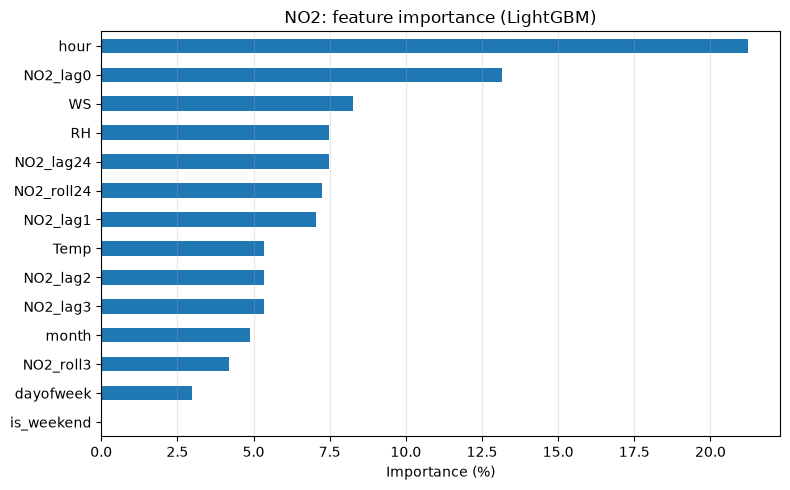

PM10 — LightGBM: top 5 features
hour         17.4
PM10_lag0    11.5
RH            8.6
WS            8.5
Temp          7.6
dtype: float64 



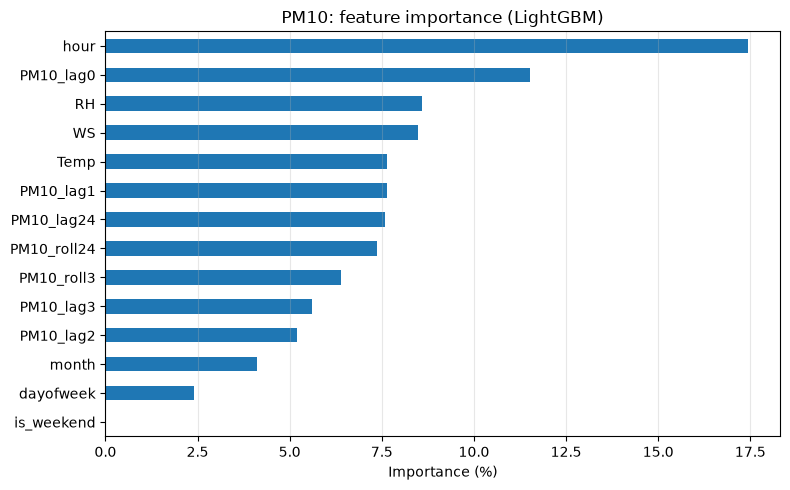

In [29]:
# Feature importance for the best model of each pollutant.

import joblib

trained_best = {}

for _, row in best_models.iterrows():

    t, name = row['Target'], row['Model']

    X_train = data[t]['train'].drop(columns='target')
    y_train = data[t]['train']['target']

    # rebuild and train the winning model
    model = model_lookup[name]()
    model.fit(X_train, y_train)
    trained_best[t] = model

    # importance as % of total
    imp = pd.Series(model.feature_importances_, index=X_train.columns)
    imp = (imp / imp.sum() * 100).sort_values()

    print(f"{t} — {name}: top 5 features")
    print(imp.sort_values(ascending=False).head(5).round(1), "\n")

    # bar chart
    imp.plot(kind='barh', figsize=(8, 5), color='tab:blue')
    plt.title(f"{t}: feature importance ({name})")
    plt.xlabel('Importance (%)')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

    # save the trained model
    joblib.dump(model, f"best_model_{t}.pkl")

In [30]:
import os
import joblib

# save compressed models into a "models" folder for the dashboard
os.makedirs("models", exist_ok=True)
for t, model in trained_best.items():
    joblib.dump(model, f"models/best_model_{t}.pkl", compress=3)
    print(t, round(os.path.getsize(f"models/best_model_{t}.pkl") / 1e6, 1), "MB")

NO2 0.3 MB
PM10 0.3 MB


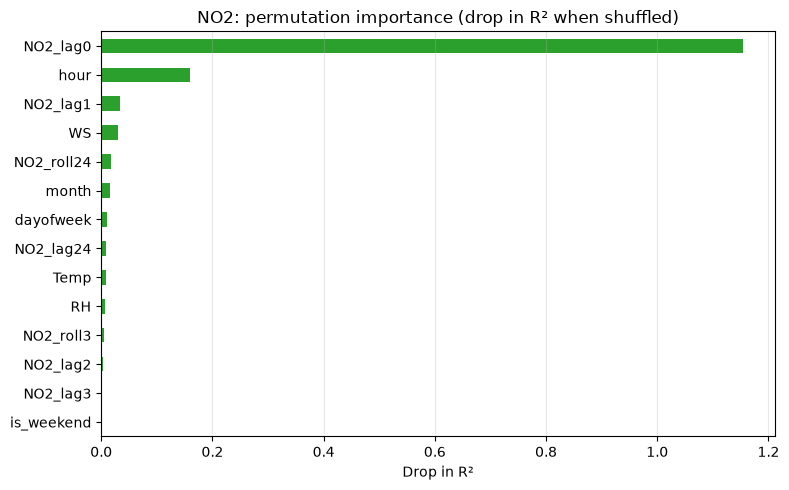

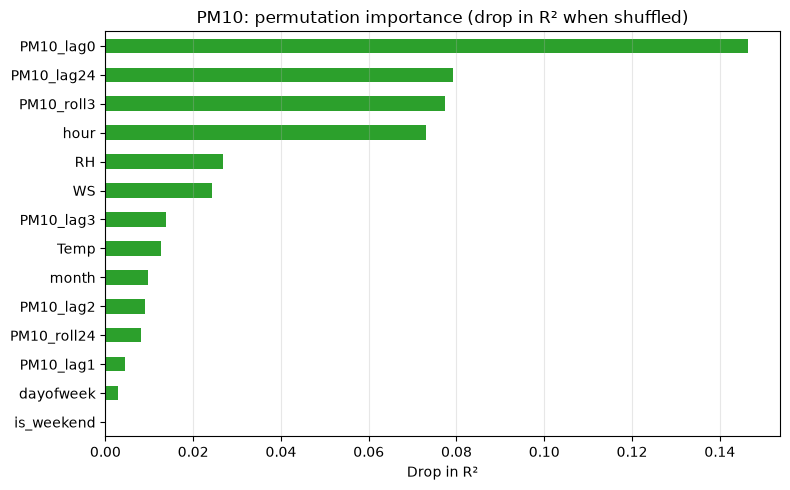

In [31]:
# Permutation importance on the test set (same method for both models).

from sklearn.inspection import permutation_importance

for t, model in trained_best.items():

    X_test = data[t]['test'].drop(columns='target')
    y_test = data[t]['test']['target']

    perm = permutation_importance(model, X_test, y_test, n_repeats=5,
                                  random_state=42, n_jobs=-1, scoring='r2')

    imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

    imp.plot(kind='barh', figsize=(8, 5), color='tab:green')
    plt.title(f"{t}: permutation importance (drop in R² when shuffled)")
    plt.xlabel('Drop in R²')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

LightGBM with all features: R² = 0.380
without PM10_lag0: R² = 0.372  (drop 0.008)
without PM10_lag24: R² = 0.365  (drop 0.015)
without hour: R² = 0.358  (drop 0.022)
without RH: R² = 0.385  (drop -0.005)
without WS: R² = 0.378  (drop 0.001)
without Temp: R² = 0.380  (drop -0.000)


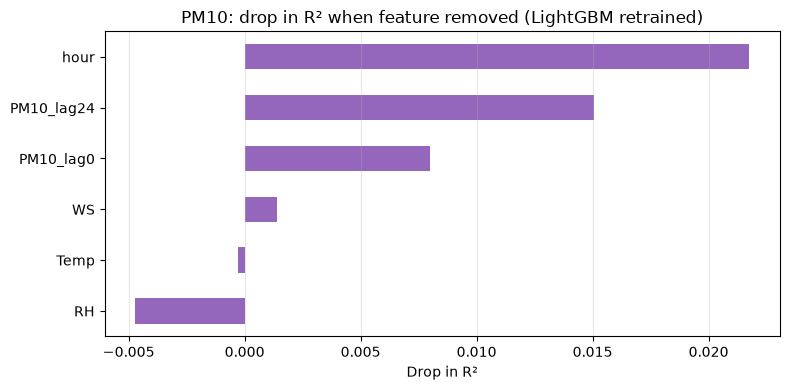

In [32]:
# Drop-column check for PM10: retrain the BEST model without each key feature
# (fixed: uses the same model type as the winner, not always Random Forest)
t = "PM10"
name = best_models.loc[best_models["Target"] == t, "Model"].iloc[0]

X_train = data[t]["train"].drop(columns="target")
y_train = data[t]["train"]["target"]
X_test = data[t]["test"].drop(columns="target")
y_test = data[t]["test"]["target"]

base_r2 = r2_score(y_test, trained_best[t].predict(X_test))
print(f"{name} with all features: R² = {base_r2:.3f}")

drops = {}
for feat in ["PM10_lag0", "PM10_lag24", "hour", "RH", "WS", "Temp"]:
    model = model_lookup[name]()
    model.fit(X_train.drop(columns=feat), y_train)
    r2 = r2_score(y_test, model.predict(X_test.drop(columns=feat)))
    drops[feat] = base_r2 - r2
    print(f"without {feat}: R² = {r2:.3f}  (drop {base_r2 - r2:.3f})")

pd.Series(drops).sort_values().plot(kind="barh", figsize=(8, 4), color="tab:purple")
plt.title(f"PM10: drop in R² when feature removed ({name} retrained)")
plt.xlabel("Drop in R²")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Group importance: remove a whole group of features, retrain, compare R².

groups = {
    'Weather': ['Temp', 'RH', 'WS'],
    'Recent pollution': ['lag0', 'lag1', 'lag2', 'lag3', 'lag24', 'roll3', 'roll24'],
    'Time': ['hour', 'month', 'dayofweek', 'is_weekend'],
}

group_results = []

for _, row in best_models.iterrows():

    t, name = row['Target'], row['Model']

    X_train = data[t]['train'].drop(columns='target')
    y_train = data[t]['train']['target']
    X_test = data[t]['test'].drop(columns='target')
    y_test = data[t]['test']['target']

    # R² with all features
    base_r2 = r2_score(y_test, trained_best[t].predict(X_test))

    for group, feats in groups.items():

        # pollution features have the pollutant name in front, e.g. NO2_lag0
        cols = [c for c in X_train.columns if c in feats or c.replace(f"{t}_", "") in feats]

        model = model_lookup[name]()
        model.fit(X_train.drop(columns=cols), y_train)
        r2 = r2_score(y_test, model.predict(X_test.drop(columns=cols)))

        group_results.append({'Target': t, 'Removed': group,
                              'R2 without': round(r2, 3), 'Drop in R2': round(base_r2 - r2, 3)})
        print(f"{t} without {group}: R² = {r2:.3f}  (drop {base_r2 - r2:.3f})")

group_df = pd.DataFrame(group_results)
group_df

NO2 without Weather: R² = 0.776  (drop 0.006)
NO2 without Recent pollution: R² = 0.251  (drop 0.531)
NO2 without Time: R² = 0.729  (drop 0.053)
PM10 without Weather: R² = 0.367  (drop 0.013)
PM10 without Recent pollution: R² = 0.036  (drop 0.344)
PM10 without Time: R² = 0.352  (drop 0.028)


,Target,Removed,R2 without,Drop in R2
0,NO2,Weather,0.776,0.006
1,NO2,Recent pollution,0.251,0.531
2,NO2,Time,0.729,0.053
3,PM10,Weather,0.367,0.013
4,PM10,Recent pollution,0.036,0.344
5,PM10,Time,0.352,0.028


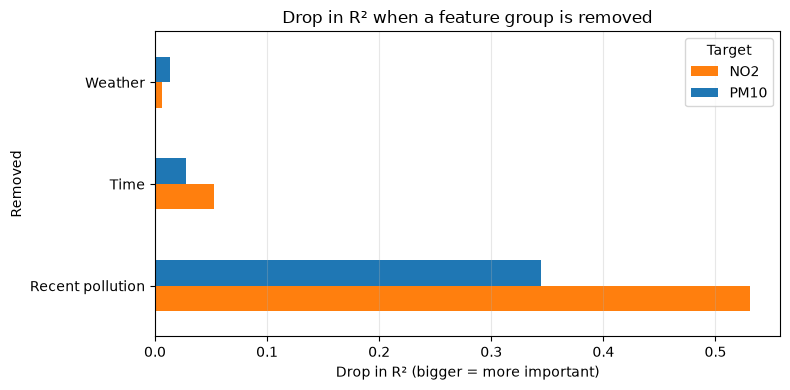

In [34]:
# Chart: drop in R² for each group, both pollutants.

group_df.pivot(index='Removed', columns='Target', values='Drop in R2').plot(
    kind='barh', figsize=(8, 4), color={'NO2': 'tab:orange', 'PM10': 'tab:blue'})
plt.title('Drop in R² when a feature group is removed')
plt.xlabel('Drop in R² (bigger = more important)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# save best-model predictions for the test set (last 20%)
rows = []
for _, row in best_models.iterrows():
    t, name = row["Target"], row["Model"]
    test = data[t]["test"]
    rows.append(pd.DataFrame({
        "datetime": test.index + pd.Timedelta(hours=1),   # hour being predicted
        "pollutant": t,
        "model": name,
        "actual": test["target"].values,
        "predicted": predictions[(t, name)],
    }))

pred_df = pd.concat(rows)
pred_df.to_csv("predictions_test.csv", index=False)
print(pred_df.shape, pred_df["datetime"].min(), "to", pred_df["datetime"].max())
pred_df.groupby(["pollutant", "model"]).size()

(50347, 5) 2017-07-15 08:00:00 to 2023-02-01 00:00:00


pollutant  model   
NO2        LightGBM    24350
PM10       LightGBM    25997
dtype: int64